# Diabetes Prediction (BRFSS 2015) - Multi-Model Comparison + Clustering

**Dataset:** CDC Behavioral Risk Factor Survey 2015 - full `diabetes_binary` file, 253,680 rows (22 features: medical flags, lifestyle, demographics). The 50/50 split (70,692 rows) is also in `Data/` for a faster run.

**Approach:** EDA + missing-data check (none found) -> **ColumnTransformer** preprocessing -> compare classifiers:

| Model | Lab |
|---|---|
| Logistic Regression | Lab 5 |
| Decision Tree - gini | Lab 2 |
| Decision Tree - entropy | Lab 2 |
| Random Forest | Lab 5 |
| **Voting Ensemble** (soft: LogReg + DT + RF) | combined |
| Linear SVM (`SVC(kernel='linear')`) | Lab 3 |
| Poly SVM (`SVC(kernel='poly')`) | Lab 3 |
| RBF SVM (`SVC(kernel='rbf')`) | Lab 3 |

Plus an **unsupervised** section: K-Means vs Agglomerative (Ward) clustering of the patient population.

**Evaluation:** stratified 5-fold cross-validation (accuracy + AUC) on the training set, per-fold chi-square & phi scores, held-out test-set metrics, per-class metrics, confusion matrices, statistical tests (chi-square of independence + paired t-test), and a final combined table for the report. Reproducible (`random_state=42`).


## 1. Imports & config


In [13]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, silhouette_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

# Parallel training: joblib (loky = separate processes) + threadpoolctl (one thread pool per worker)
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use("seaborn-v0_8-white")

# ---- Config ----
SEED = 42
TEST_SIZE = 0.30
N_FOLDS = 5
MAX_DEPTH = 8
N_ESTIMATORS = 200
N_JOBS = 16  # use all 16 cores for model-level parallelism                      # parallel workers for model training (joblib loky)
DATA_PATH = "Data/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

print("Setup complete.")
print(f"N_JOBS (parallel workers): {N_JOBS}")


Setup complete.
N_JOBS (parallel workers): 16


## 2. Load the dataset

Three files ship in `Data/`: the full binary file (253,680 rows - **used here**), the 50/50 balanced split (70,692 rows), and the 3-class 0/1/2 file (253,680 rows). The full binary file wins on data volume; `class_weight="balanced"` handles its 86/14 imbalance.


In [14]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()


Shape: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [15]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth              70692 no

In [16]:
# Target balance + a quick look at the two strongest medical flags
print("--- Diabetes_binary ---")
print(df["Diabetes_binary"].value_counts(dropna=False))
print("\n--- HighBP x Diabetes ---")
print(pd.crosstab(df["HighBP"], df["Diabetes_binary"]))
print("\n--- HighChol x Diabetes ---")
print(pd.crosstab(df["HighChol"], df["Diabetes_binary"]))


--- Diabetes_binary ---
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

--- HighBP x Diabetes ---
Diabetes_binary    0.0    1.0
HighBP                       
0.0              22118   8742
1.0              13228  26604

--- HighChol x Diabetes ---
Diabetes_binary    0.0    1.0
HighChol                     
0.0              21869  11660
1.0              13477  23686


## 3. Missing data check

A quick check for missing values before modeling. **There are none** - all 253,680 rows and all 22 columns are complete, so no imputation is required. We continue straight to preprocessing.


In [17]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (100 * df.isnull().sum() / len(df)).round(2),
}).sort_values("missing_pct", ascending=False)
print(missing)
print("\nTotal missing values:", int(df.isnull().sum().sum()))
print("-> No missing data. Continuing without imputation.")


                      missing_count  missing_pct
Diabetes_binary                   0          0.0
HighBP                            0          0.0
HighChol                          0          0.0
CholCheck                         0          0.0
BMI                               0          0.0
Smoker                            0          0.0
Stroke                            0          0.0
HeartDiseaseorAttack              0          0.0
PhysActivity                      0          0.0
Fruits                            0          0.0
Veggies                           0          0.0
HvyAlcoholConsump                 0          0.0
AnyHealthcare                     0          0.0
NoDocbcCost                       0          0.0
GenHlth                           0          0.0
MentHlth                          0          0.0
PhysHlth                          0          0.0
DiffWalk                          0          0.0
Sex                               0          0.0
Age                 

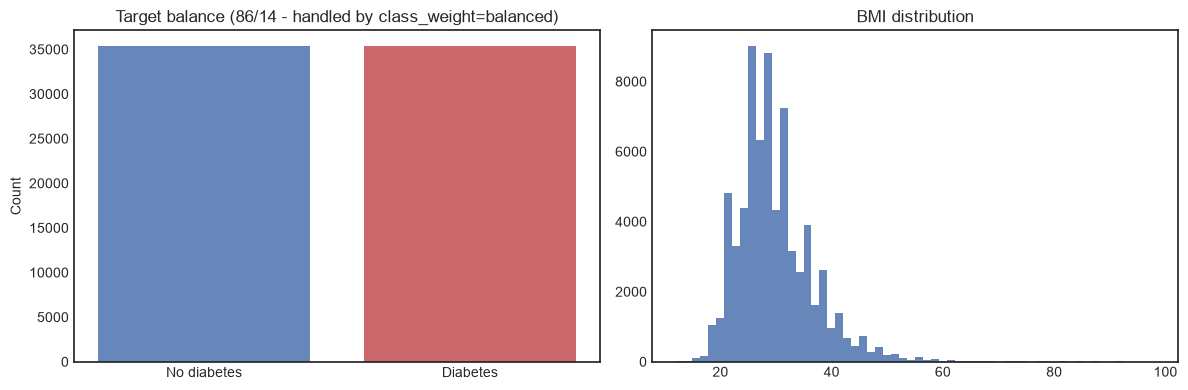

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns_count = df["Diabetes_binary"].value_counts().reindex([0, 1])
axes[0].bar([0, 1], sns_count.values, color=["#4C72B0", "#C44E52"], alpha=0.85)
axes[0].set_xticks([0, 1], ["No diabetes", "Diabetes"])
axes[0].set_title("Target balance (86/14 - handled by class_weight=balanced)")
axes[0].set_ylabel("Count")
axes[1].hist(df["BMI"], bins=60, color="#4C72B0", alpha=0.85)
axes[1].set_title("BMI distribution")
plt.tight_layout()
plt.show()


In [19]:
# Correlation of numeric columns with the target
num_cols = ["BMI", "HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]
corr = df[num_cols + ["Diabetes_binary"]].corr()["Diabetes_binary"].drop("Diabetes_binary")
print(corr.round(4))


BMI                     0.2934
HighBP                  0.3815
HighChol                0.2892
Stroke                  0.1254
HeartDiseaseorAttack    0.2115
Name: Diabetes_binary, dtype: float64


## 4. Feature split - numerical vs categorical

`Age` and `Income` are **string ranges** (e.g. `"25-34"`, `"75000-149999"`), so they go to the categorical side. Everything else is numeric or a 0/1 flag.


In [20]:
TARGET = "Diabetes_binary"
y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET])

numerical_features = [
    "BMI", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "GenHlth", "MentHlth", "PhysHlth", "DiffWalk",
]
categorical_features = [c for c in X.columns if c not in numerical_features]
print(f"Numerical  ({len(numerical_features)}): {numerical_features}")
print(f"Categorical ({len(categorical_features)}): {categorical_features}")


Numerical  (17): ['BMI', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk']
Categorical (4): ['Sex', 'Age', 'Education', 'Income']


## 5. Preprocessing pipeline

- **Numerical:** `StandardScaler()`
- **Categorical:** `OneHotEncoder(drop="first", handle_unknown="ignore")`

Section 3 confirmed this file has **no missing values**, so no imputer is active. The `ColumnTransformer` is rebuilt **inside every classifier Pipeline**, so it is always fitted on the CV train fold only - no data leakage.


In [21]:
def build_preprocessor():
    # --- Imputation (commented out: this file has NO missing values, see Section 3) ---
    # If the data had gaps we would add these steps, and here is why:
    #
    #   Numeric columns -> SimpleImputer(strategy="median")
    #     * Robust to the right-skewed distributions in this data (e.g. BMI, MentHlth).
    #       The mean is pulled by the upper tail, so it would inject an unrepresentative
    #       value; the median (50th percentile) is not.
    #     * Fitted per CV fold on that fold's training rows only, so it stays leak-free.
    #
    #   Categorical columns -> SimpleImputer(strategy="most_frequent")
    #     * Nominal categories have no numeric "middle" to interpolate to - the only
    #       sensible fill is a real category, and the mode is the maximum-likelihood one.
    #     * Keeps OneHotEncoder from seeing NaNs (which would otherwise crash or drop columns).
    #
    # Uncomment to enable:
    #   ("imputer", SimpleImputer(strategy="median")),            # in the numeric pipeline
    #   ("imputer", SimpleImputer(strategy="most_frequent")),     # in the categorical pipeline
    num = Pipeline([
        ("scaler", StandardScaler()),
    ])
    cat = Pipeline([
        ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        [("num", num, numerical_features),
         ("cat", cat, categorical_features)],
        remainder="drop")

# quick sanity check of the feature space
X_prep = build_preprocessor().fit_transform(X, y)
print("Preprocessed feature matrix:", X_prep.shape)
print("NaNs in feature matrix:", int(np.isnan(X_prep).sum()), "(0 - data is complete)")


Preprocessed feature matrix: (70692, 42)
NaNs in feature matrix: 0 (0 - data is complete)


## 6. Train/test split (stratified)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape[0]}   Test: {X_test.shape[0]}")
print(f"Train class dist: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Test  class dist: {dict(zip(*np.unique(y_test, return_counts=True)))}")


Train: 49484   Test: 21208
Train class dist: {np.int64(0): np.int64(24742), np.int64(1): np.int64(24742)}
Test  class dist: {np.int64(0): np.int64(10604), np.int64(1): np.int64(10604)}


## 7. Classifiers (only from CSE-4116)

Each is wrapped in a `Pipeline` (preprocessor -> classifier) so scaling + encoding are fitted **only on training data** inside cross-validation - no data leakage. The three SVMs use `probability=True` so that AUC is comparable across all models.

**Voting Ensemble:** a `VotingClassifier(voting="soft")` over Logistic Regression + Decision Tree + Random Forest. Each base estimator carries its own `Pipeline(preprocessor -> classifier)`, so preprocessing is still fitted per-estimator inside CV - the ensemble is just a wrapper around three leak-free pipelines.


In [23]:
def build_models():
    logreg = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
    ])
    dt_gini = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    dt_entropy = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    rf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                       n_jobs=-1, random_state=SEED, class_weight="balanced")),
    ])
    svm_linear = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="linear", C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_poly = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="poly", degree=3, C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_rbf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    # --- Soft-voting ensemble over 3 diverse base models (each with its own preprocessor) ---
    voting = VotingClassifier(
        voting="soft",
        estimators=[
            ("logreg", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
            ])),
            ("dt", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH,
                                               random_state=SEED, class_weight="balanced")),
            ])),
            ("rf", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                               n_jobs=-1, random_state=SEED, class_weight="balanced")),
            ])),
        ],
    )
    return {
        "Logistic Reg":   logreg,
        "DT (gini)":      dt_gini,
        "DT (entropy)":   dt_entropy,
        "Random Forest":  rf,
        "Linear SVM":     svm_linear,
        "Poly SVM":       svm_poly,
        "RBF SVM":        svm_rbf,
        "Ensemble (vote)": voting,
    }

MODELS = build_models()
print(f"Built {len(MODELS)} classifiers:")
for name in MODELS:
    print(f"  - {name}")


Built 8 classifiers:
  - Logistic Reg
  - DT (gini)
  - DT (entropy)
  - Random Forest
  - Linear SVM
  - Poly SVM
  - RBF SVM
  - Ensemble (vote)


## 8. Cross-validation (5-fold stratified)

`cross_val_score` on the **training** set with `accuracy` and `roc_auc` (AUC available for every model thanks to `probability=True` on the SVMs).

**Parallel:** the models are trained concurrently with `joblib parallel_config(backend="loky")` - one process per model. Each worker caps its own thread pool with `threadpool_limits(limits=1)` so the BLAS/OpenMP threads inside one worker don't oversubscribe the CPU. `clone()` guarantees each worker fits a fresh copy (no shared state across processes).


In [24]:
def _cv_one(name, model, X_train, y_train, cv):
    """Single 5-fold pass computing both accuracy and AUC simultaneously."""
    print(f"  [CV] {name:14s} - training 5-fold CV...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        est = clone(model)
        scoring = {"accuracy": "accuracy"}
        if hasattr(est, "predict_proba") or hasattr(est, "decision_function"):
            scoring["roc_auc"] = "roc_auc"
        scores = cross_validate(
            est, X_train, y_train, cv=cv,
            scoring=scoring, n_jobs=1, error_score="raise",
        )
    dt = time.perf_counter() - t0
    print(f"  [CV] {name:14s} - done in {dt:.1f}s", flush=True)
    return name, {
        "cv_acc_mean": scores["test_accuracy"].mean(),
        "cv_acc_std": scores["test_accuracy"].std(),
        "cv_auc_mean": scores["test_roc_auc"].mean() if "test_roc_auc" in scores else float("nan"),
        "cv_auc_std": scores["test_roc_auc"].std() if "test_roc_auc" in scores else float("nan"),
        "cv_time_s": dt,
    }

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
print(f"Starting 5-fold cross-validation for {len(MODELS)} models ({N_JOBS} parallel workers)...")

with parallel_config(n_jobs=N_JOBS, backend="loky"):
    cv_raw = Parallel()(
        delayed(_cv_one)(name, model, X_train, y_train, cv)
        for name, model in MODELS.items()
    )

cv_rows = [{"model": name, **stats} for name, stats in cv_raw]
cv_results = pd.DataFrame(cv_rows).set_index("model")

for name in MODELS:
    r = cv_results.loc[name]
    auc = f"{r.cv_auc_mean:.4f} +/- {r.cv_auc_std:.4f}" if not pd.isna(r.cv_auc_mean) else "n/a"
    print(f"  {name:14s}  acc={r.cv_acc_mean:.4f} +/- {r.cv_acc_std:.4f}   "
          f"auc={auc}   ({r.cv_time_s:.1f} s)")

print()
print("--- Cross-validation summary ---")
print(cv_results.to_string())


Starting 5-fold cross-validation for 8 models (16 parallel workers)...


KeyboardInterrupt: 

## 8b. Cross-validation with chi-square and phi scores

Two statistical association measures between **predicted** and **true** class, computed on each CV fold's confusion matrix:

- **Chi-square (chi2)**: `chi2 = sum (O - E)2 / E`. Higher = stronger dependence between prediction and truth (i.e. not random). Scales with sample size.
- **Phi coefficient (phi)**: the Pearson correlation of two binary variables (the 2x2 special case of Cramer's V). Range [-1, +1]; magnitude = strength of association. Bounded and comparable across folds, unlike chi2.

Both are complementary to accuracy: they quantify *how strongly* the model's output tracks the label, independent of the arbitrary 0.5 threshold. (Same technique as the chi-square section of the chi-square lab.)


In [ ]:
def chi2_and_phi(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    a, b = cm[0, 0], cm[0, 1]
    c, d = cm[1, 0], cm[1, 1]
    n = a + b + c + d
    # Chi-square (no Yates correction)
    denom2 = (a + b) * (c + d) * (a + c) * (b + d)
    chi2 = (n * (a * d - b * c) ** 2) / denom2 if denom2 > 0 else float('nan')
    # Phi coefficient
    denom = denom2 ** 0.5
    phi = (a * d - b * c) / denom if denom > 0 else float('nan')
    return chi2, phi

def _fold_scores(model, X_train, y_train, cv):
    chis, phis = [], []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        yp = model.predict(X_train.iloc[va_idx])
        c, p = chi2_and_phi(y_train.iloc[va_idx], yp)
        chis.append(c)
        phis.append(p)
    return np.array(chis), np.array(phis)

def _chi2_phi_one(name, model, X_train, y_train, cv):
    print(f"  [8b] {name:14s} - computing chi2/phi over 5 folds...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        chis, phis = _fold_scores(clone(model), X_train, y_train, cv)
    dt = time.perf_counter() - t0
    print(f"  [8b] {name:14s} - done in {dt:.1f}s", flush=True)
    return name, {
        "chi2_mean": chis.mean(), "chi2_std": chis.std(),
        "phi_mean": phis.mean(), "phi_std": phis.std(),
        "time_s": dt,
    }

print(f"Starting chi2/phi CV for {len(MODELS)} models ({N_JOBS} parallel workers)...")
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    chi2_raw = Parallel()(delayed(_chi2_phi_one)(name, model, X_train, y_train, cv) for name, model in MODELS.items())
chi2_rows = [{"model": name, **stats_} for name, stats_ in chi2_raw]
chi2_results = pd.DataFrame(chi2_rows).set_index("model")
for name in MODELS:
    r = chi2_results.loc[name]
    print(f"  {name:14s}  chi2={r.chi2_mean:9.2f} +/- {r.chi2_std:8.2f}   phi={r.phi_mean:+.4f} +/- {r.phi_std:.4f}   ({r.time_s:.1f} s)")
print()
print("--- Chi-square & Phi CV summary (sorted by phi) ---")
print(chi2_results.sort_values("phi_mean", ascending=False).round(4).to_string())


## 9. Fit on train, evaluate on held-out test set


In [ ]:
def _fit_one(name, model, X_train, y_train, X_test, y_test):
    print(f"  [Fit] {name:14s} - training...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        m = clone(model)
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="macro")
        prec = precision_score(y_test, y_pred, average="macro")
        rec = recall_score(y_test, y_pred, average="macro")
        try:
            auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
        except Exception:
            auc = float("nan")
    fit_dt = time.perf_counter() - t0
    print(f"  [Fit] {name:14s} - done in {fit_dt:.1f}s", flush=True)
    return name, m, y_pred, dict(acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, fit_s=fit_dt)

print(f"Fitting {len(MODELS)} models on training set ({N_JOBS} parallel workers)...")
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    fit_raw = Parallel()(delayed(_fit_one)(name, model, X_train, y_train, X_test, y_test) for name, model in MODELS.items())

fitted_models = {}
y_pred_all = {}
test_results = []
for name, m, y_pred, m_ in fit_raw:
    fitted_models[name] = m
    y_pred_all[name] = y_pred
    test_results.append(dict(model=name, **m_))
    print(f"  {name:14s}  acc={m_['acc']:.4f}  f1={m_['f1']:.4f}  prec={m_['prec']:.4f}  "
          f"rec={m_['rec']:.4f}  auc={m_['auc']:.4f}  fit={m_['fit_s']:.1f}s")

test_df = pd.DataFrame(test_results).set_index("model")
print("\n--- Test-set summary ---")
print(test_df.round(4).to_string())


## 9b. Chi-square & Phi on the held-out test set

Same association measures, now computed once on the full test split using each model's stored predictions. These are single-point estimates (no +/- std) - the CV values in section 8b carry the fold-to-fold variance.


In [ ]:
test_chi2_rows = []
for name, y_pred in y_pred_all.items():
    c2, phi = chi2_and_phi(y_test, y_pred)
    test_chi2_rows.append({"model": name, "chi2": c2, "phi": phi})

test_chi2 = pd.DataFrame(test_chi2_rows).set_index("model")
print("--- Chi-square & Phi on test set (sorted by phi) ---")
print(test_chi2.sort_values("phi", ascending=False).round(4).to_string())


## 9c. Full-dataset evaluation (fit on 100% of the data)

Each model is fit on **all rows** and evaluated on the same data (in-sample). **Caveat:** because fit == eval here, these numbers are optimistic upper bounds - the held-out test-set sections (9, 9b) are the honest generalization estimate. The in-sample view still ranks models consistently and shows each one's ceiling on this feature set.


In [ ]:
def _full_one(name, model, X, y):
    print(f"  [Full] {name:14s} - fitting on full dataset...", flush=True)
    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        m = clone(model)
        m.fit(X, y)
        yp = m.predict(X)
        acc = accuracy_score(y, yp)
        f1 = f1_score(y, yp, average="macro")
        prec = precision_score(y, yp, average="macro")
        rec = recall_score(y, yp, average="macro")
        try:
            auc = roc_auc_score(y, m.predict_proba(X)[:, 1])
        except Exception:
            auc = float("nan")
        c2, phi = chi2_and_phi(y, yp)
    fit_dt = time.perf_counter() - t0
    print(f"  [Full] {name:14s} - done in {fit_dt:.1f}s", flush=True)
    return name, yp, dict(acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, chi2=c2, phi=phi, fit_s=fit_dt)

print(f"Fitting {len(MODELS)} models on full dataset ({N_JOBS} parallel workers)...")
with parallel_config(n_jobs=N_JOBS, backend="loky"):
    full_raw = Parallel()(delayed(_full_one)(name, model, X, y) for name, model in MODELS.items())
y_pred_full = {}
full_rows = []
for name, yp, m_ in full_raw:
    y_pred_full[name] = yp
    full_rows.append(dict(model=name, **m_))
    print(f"  {name:14s}  acc={m_['acc']:.4f}  f1={m_['f1']:.4f}  auc={m_['auc']:.4f}  chi2={m_['chi2']:.1f}  phi={m_['phi']:.4f}  fit={m_['fit_s']:.1f}s")

full_df = pd.DataFrame(full_rows).set_index("model")
print()
print("=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===")
print(full_df.sort_values("acc", ascending=False).round(4).to_string())


## 9d. Full-dataset confusion matrices (in-sample)


In [ ]:
n_models = len(y_pred_full)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_full.items()):
    cm = pd.DataFrame(confusion_matrix(y, yp, labels=[0, 1]),
                      index=["No", "Yes"], columns=["No", "Yes"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.grid(False)
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on full dataset (in-sample; rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()


## 10. Per-class metrics + confusion matrices (test set)


In [ ]:
per_class = pd.DataFrame(index=list(MODELS.keys()),
                         columns=["no_diag_prec", "no_diag_rec", "no_diag_f1",
                                  "diag_prec", "diag_rec", "diag_f1"])
for name, yp in y_pred_all.items():
    per_class.loc[name, "no_diag_prec"] = precision_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "no_diag_rec"]  = recall_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "no_diag_f1"]   = f1_score(y_test, yp, labels=[0], zero_division=0)
    per_class.loc[name, "diag_prec"]    = precision_score(y_test, yp, labels=[1], zero_division=0)
    per_class.loc[name, "diag_rec"]     = recall_score(y_test, yp, labels=[1], zero_division=0)
    per_class.loc[name, "diag_f1"]      = f1_score(y_test, yp, labels=[1], zero_division=0)
print("--- Per-class test metrics ---")
print(per_class.round(4).to_string())

n_models = len(y_pred_all)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_all.items()):
    cm = pd.DataFrame(confusion_matrix(y_test, yp, labels=[0, 1]),
                      index=["No", "Yes"], columns=["No", "Yes"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.grid(False)
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on test set (rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()


## 11. Decision trees deep-dive

Gini vs entropy feature importances + cost-complexity pruning (CCP).


In [ ]:
def _tree_importances(name):
    clf = fitted_models[name].named_steps["clf"]
    prep = fitted_models[name].named_steps["prep"]
    return pd.Series(clf.feature_importances_, index=prep.get_feature_names_out())

imp_gini = _tree_importances("DT (gini)")
imp_ent = _tree_importances("DT (entropy)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
imp_gini.nlargest(10).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("DT (gini) - top 10 feature importances")
imp_ent.nlargest(10).sort_values().plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("DT (entropy) - top 10 feature importances")
plt.tight_layout()
plt.show()


In [ ]:
# Cost-complexity pruning path (CCP) for the gini tree
base = DecisionTreeClassifier(criterion="gini", random_state=SEED, class_weight="balanced")
path = base.cost_complexity_pruning_path(
    build_preprocessor().fit_transform(X_train, y_train), y_train)
alphas = path.ccs_alphas

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_acc, test_acc = [], []
for alpha in alphas:
    p = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="gini", ccp_alpha=alpha,
                                       random_state=SEED, class_weight="balanced")),
    ])
    train_acc.append(cross_val_score(p, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean())
    p.fit(X_train, y_train)
    test_acc.append(p.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, train_acc, label="Train accuracy", lw=2, color="#4C72B0")
ax.plot(alphas, test_acc, label="Test accuracy", lw=2, color="#C44E52")
ax.set_xscale("log")
ax.set_xlabel("ccp_alpha (tree complexity)")
ax.set_ylabel("Accuracy")
ax.legend()
ax.set_title("CCP pruning path - DT (gini) on diabetes")
plt.tight_layout()
plt.show()


## 12. Clustering the patient population

Unsupervised view of the same data: cluster the preprocessed patients with **K-Means** and **Agglomerative (Ward)**. No labels are used - this profiles population structure, not the diabetes outcome. We pick `k` via the silhouette score, then compare the two algorithms with silhouette + ARI + NMI.


In [ ]:
X_full = build_preprocessor().fit_transform(X, y)

sil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lab = km.fit_predict(X_full)
    sil.append((k, silhouette_score(X_full, lab)))
    print(f"  k={k}   silhouette={silhouette_score(X_full, lab):.4f}")

best_k = max(sil, key=lambda t: t[1])[0]
print("\nBest k:", best_k)

km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED)
kmeans_labels = km.fit_predict(X_full)
pd.Series(kmeans_labels).value_counts().sort_index()


In [ ]:
agg = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg.fit_predict(X_full)

print("KMeans        silhouette:", round(silhouette_score(X_full, kmeans_labels), 4))
print("Agglomerative silhouette:", round(silhouette_score(X_full, agg_labels), 4))
print("ARI (kmeans vs agg)  :", round(adjusted_rand_score(kmeans_labels, agg_labels), 4))
print("NMI (kmeans vs agg)  :", round(normalized_mutual_info_score(kmeans_labels, agg_labels), 4))


In [ ]:
# Profile of each k-means cluster on the raw, interpretable columns
cluster_df = pd.DataFrame({
    "cluster": kmeans_labels,
    "BMI": df["BMI"],
    "Smoker": df["Smoker"],
    "HighBP": df["HighBP"],
    "Diabetes": y.values,
}).groupby("cluster").mean().round(2)
print(cluster_df)


In [ ]:
pca = PCA(n_components=2, random_state=SEED)
X2 = pca.fit_transform(X_full)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=kmeans_labels, cmap="tab10", s=8, alpha=0.7)
axes[0].set_title(f"K-Means (k={best_k}) - PCA view")
axes[1].scatter(X2[:, 0], X2[:, 1], c=agg_labels, cmap="tab10", s=8, alpha=0.7)
axes[1].set_title(f"Agglomerative Ward (k={best_k}) - PCA view")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()


## 13. Statistical tests

### 13a. Chi-square test of independence - `Sex` vs `Diabetes_binary`

Standard contingency-table test of independence.


In [ ]:
ct = pd.crosstab(df["Sex"], df["Diabetes_binary"])
chi2, p_value, dof, expected = chi2_contingency(ct)
print(ct)
print(f"Chi-square: {chi2:.3f}   dof: {dof}   p-value: {p_value}")
alpha = 0.05
print("Reject H0 (Sex and diabetes are statistically associated)." if p_value < alpha
      else "Do not reject H0 (no significant Sex-diabetes association).")


In [ ]:
# Same test for the strongest medical flag
ct2 = pd.crosstab(df["HighBP"], df["Diabetes_binary"])
chi2b, pb, dof2, _ = chi2_contingency(ct2)
print(ct2)
print(f"HighBP vs Diabetes - Chi-square: {chi2b:.3f}   p-value: {pb}")
print("Reject H0 (HighBP and diabetes are statistically associated)." if pb < 0.05
      else "Do not reject H0.")


### 13b. Paired t-test - Logistic Regression vs Random Forest (paired CV scores)

Five **paired** 5-fold accuracy scores -> `stats.ttest_rel`.


In [ ]:
lr = build_models()["Logistic Reg"]
rf = build_models()["Random Forest"]

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
lr_scores = cross_val_score(lr, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
rf_scores = cross_val_score(rf, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

t, p = stats.ttest_rel(lr_scores, rf_scores)
print("LogReg CV acc:", np.round(lr_scores, 4))
print("RF     CV acc:", np.round(rf_scores, 4))
print(f"Paired t = {t:.4f}, p = {p:.4f}")
print("Significant difference (p < 0.05)" if p < 0.05
      else "No significant difference between LogReg and RF (p >= 0.05)")


## 14. Bar-chart comparison


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(MODELS.keys())
cv_acc = cv_results.reindex(names)["cv_acc_mean"].values
cv_std = cv_results.reindex(names)["cv_acc_std"].values
test_acc = test_df.reindex(names)["acc"].values

x = np.arange(len(names))
w = 0.38
ax.bar(x - w/2, cv_acc, w, yerr=cv_std, capsize=3, label="CV mean (5-fold) +/- std", color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, test_acc, w, label="Test-set accuracy", color="#DD8452", alpha=0.85)
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("BRFSS 2015 diabetes - model comparison (CSE-4116 algorithms only)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 15. Final combined table - for the report


In [ ]:
final = cv_results.reindex(list(MODELS.keys()))
final["test_acc"] = test_df.reindex(list(MODELS.keys()))["acc"]
final["test_f1"]  = test_df.reindex(list(MODELS.keys()))["f1"]
final["test_auc"] = test_df.reindex(list(MODELS.keys()))["auc"]
final["test_chi2"] = test_chi2.reindex(list(MODELS.keys()))["chi2"]
final["test_phi"]  = test_chi2.reindex(list(MODELS.keys()))["phi"]
final = final[["cv_acc_mean", "cv_acc_std", "cv_auc_mean", "test_acc", "test_f1", "test_auc",
               "test_chi2", "test_phi", "cv_time_s"]]
final.columns = ["CV Acc", "+/-std", "CV AUC", "Test Acc", "Test F1", "Test AUC",
                 "Test Chi2", "Test Phi", "CV time (s)"]
final = final.sort_values("Test Acc", ascending=False)
print("\n=== FINAL COMPARISON (sorted by Test Acc) ===")
print(final.round(4).to_string())
best = final.index[0]
print(f"\n>>> Best model by test accuracy: {best}  ({final.loc[best, 'Test Acc']:.4f})")


## 16. Notes

- **Why the full binary file?** Most data (253,680 rows). `class_weight="balanced"` handles the 86/14 imbalance. Switch `DATA_PATH` to the `..._5050split_...` file for a faster, balanced run.
- **Missing data:** Section 3 verified the file has zero missing values, so no imputation was required. The imputer steps are documented (commented) in Section 5 with the rationale for why median / most-frequent would be used if the data had gaps.
- **String ranges:** `Age` and `Income` are ordinal string ranges (`"25-34"`, `"75000-149999"`); treated as categoricals. Could be mapped to midpoints if an ordinal encoding is preferred.
- **Leakage control:** the `ColumnTransformer` is rebuilt inside every `Pipeline`, so fitting always happens on the CV train fold only.
- **AUC for all models:** SVMs use `probability=True` (slower, but gives calibrated `predict_proba`) so `roc_auc` is comparable across the zoo.
- **Clustering** is unsupervised and label-free - it profiles the patient population, not the diabetes outcome.
- **Hyperparameters:** `C=1.0` (SVM/LogReg), `max_depth=8` (DT), `n_estimators=200, max_depth=15` (RF). Wrap in `GridSearchCV` for a tuned run.
- **Reproducibility:** `random_state=42` everywhere; `n_jobs=-1`; K-Means `n_init=10`.

